# 01 - Data cleaning and EDA
Cleans the raw Online Retail II transactions and explores them. All logic lives in `src/`; this notebook only calls it and shows results.

In [1]:
import sys
sys.path.append('../src')

import config
from data_cleaning import run_cleaning
import eda

%matplotlib inline

## 1. Cleaning
The cancellations table is saved **before** cancellations are removed, because we need it later for `return_rate`.

In [2]:
clean, cancellations = run_cleaning()

Starting rows: 1,067,371
Cancellations table kept: 17,933 product rows, 7,282 invoices

Removal steps:
  - removed    19,494 rows: cancelled invoices (start with 'C')


  - removed         6 rows: bad-debt adjustment invoices (start with 'A')
  - removed   242,251 rows: missing customer_id (guest checkout)


    non-product codes found (code: rows):
      POST: 1,838
      M: 716
      C2: 253
      BANK CHARGES: 32
      ADJUST: 32
      PADS: 18
      DOT: 16
      TEST001: 11
      D: 5
      ADJUST2: 3
      TEST002: 1
  - removed     2,925 rows: non-product stock codes (fees, postage, adjustments...)
  - removed         0 rows: quantity <= 0
  - removed        61 rows: price <= 0


  - removed    26,055 rows: exact duplicate rows



Final clean rows: 776,579


Saved: D:\SEM-7\churn-clv-predictor\data\processed\transactions_clean.parquet
Saved: D:\SEM-7\churn-clv-predictor\data\processed\cancellations.parquet


In [3]:
clean.head()

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,total_price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [4]:
customers = eda.customer_summary(clean)
print(f'Customers: {len(customers):,}   Orders: {clean["invoice"].nunique():,}')
customers.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1)

Customers: 5,852   Orders: 36,594


,orders,total_spend
count,5852.0,5852.0
mean,6.3,2916.7
std,12.7,14306.9
min,1.0,3.0
25%,1.0,339.6
50%,3.0,856.0
75%,7.0,2241.0
90%,13.0,5392.8
99%,46.0,28631.1
max,373.0,580987.0


## 2. Monthly revenue - one chart in three tools

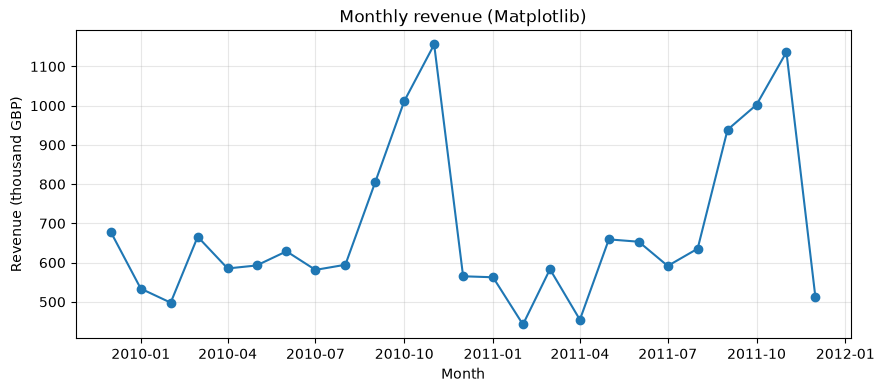

In [5]:
eda.plot_monthly_revenue_matplotlib(clean);

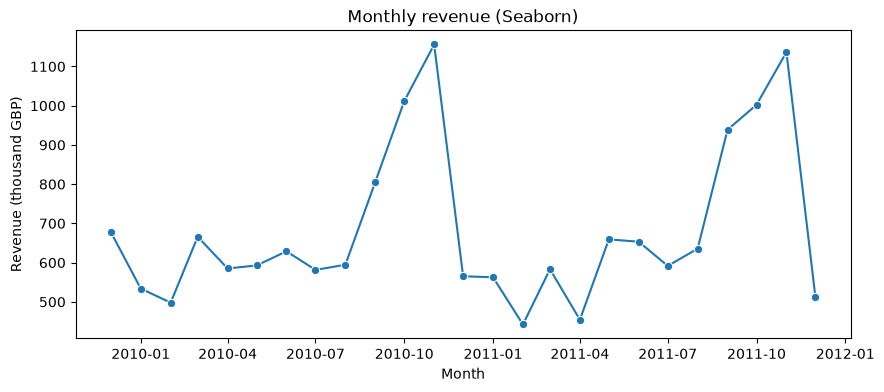

In [6]:
eda.plot_monthly_revenue_seaborn(clean);

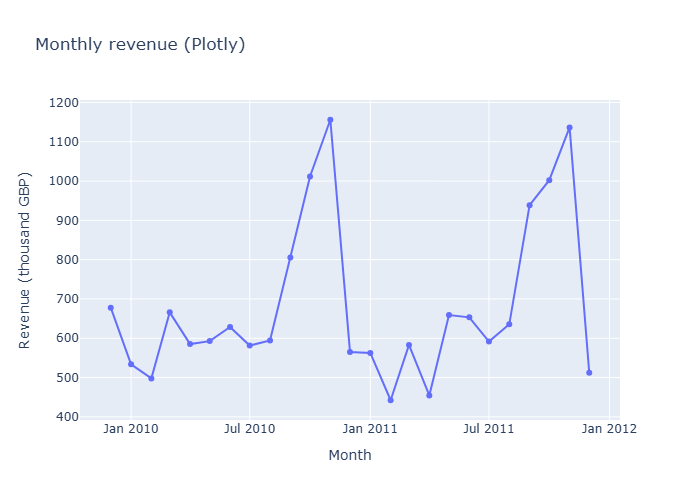

In [7]:
eda.plot_monthly_revenue_plotly(clean).show(renderer='png')

**What it shows:** Revenue is fairly flat at roughly 450-700k GBP per month for most of the year, then climbs every September to November (peak about 1.16M in Nov 2010 and 1.14M in Nov 2011) - a strong Christmas season. The last point (Dec 2011) is low only because the data stops on 9 December 2011.

**Matplotlib vs Seaborn vs Plotly:**
- *Matplotlib* - lowest level, full control, but every label and style must be set by hand.
- *Seaborn* - built on Matplotlib; works directly with DataFrame columns and gives nicer defaults with less code. Best for statistical plots (box, hist, bar with groups).
- *Plotly* - interactive (hover, zoom) in the notebook and in Streamlit; saving a static PNG needs the extra `kaleido` package. Best for the app/dashboard.

We use Matplotlib/Seaborn for report figures and Plotly for the Streamlit app.

## 3. Top 10 countries by revenue

country
United Kingdom    83.7
EIRE               3.4
Netherlands        3.2
Germany            2.2
France             1.8
Australia          1.0
Spain              0.6
Switzerland        0.5
Sweden             0.5
Denmark            0.4
Name: % of revenue, dtype: float64

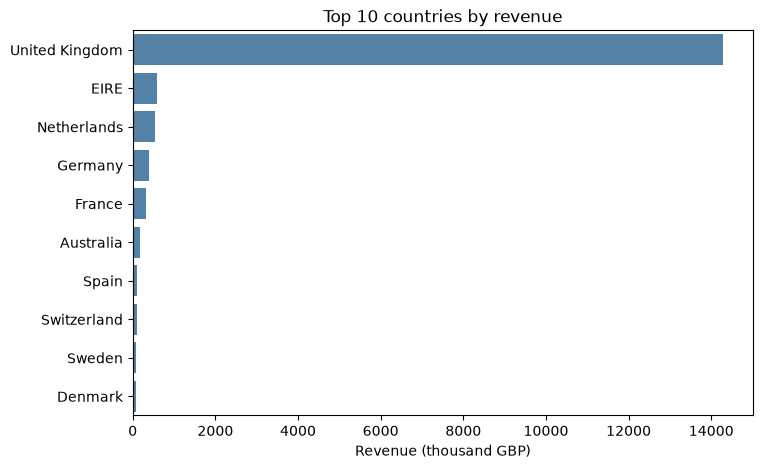

In [8]:
fig, top_countries = eda.plot_top_countries(clean)
(top_countries / (clean['total_price'].sum() / 1000) * 100).round(1).rename('% of revenue')

**What it shows:** The United Kingdom alone brings about 84% of revenue; the next countries (EIRE, Netherlands, Germany, France) are each only 2-3.5%. This is why we use a simple UK vs. international feature instead of one column per country.

## 4. Top 10 products by quantity

stock_code
84077     105185
85099B     93436
85123A     91814
21212      89850
23843      80995
84879      78234
23166      77916
22197      76944
17003      70082
21977      54592
Name: quantity, dtype: int64

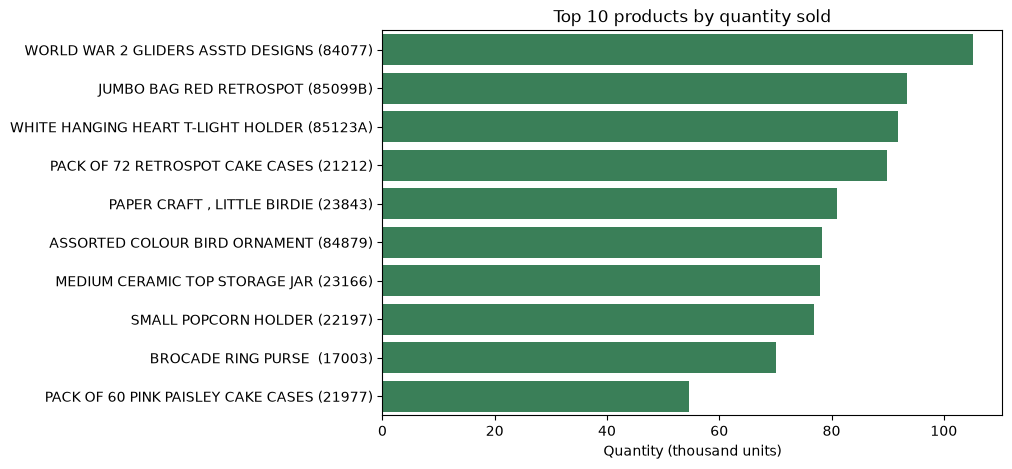

In [9]:
fig, top_products = eda.plot_top_products(clean)
top_products

**What it shows:** The best sellers by units are cheap, small gift and party items: WORLD WAR 2 GLIDERS (about 105k units), JUMBO BAG RED RETROSPOT, WHITE HANGING HEART T-LIGHT HOLDER and cake cases. These are bought in bulk, which fits the many wholesale customers in this dataset.

## 5. Orders and spend per customer

Customers with only one order: 27.6%


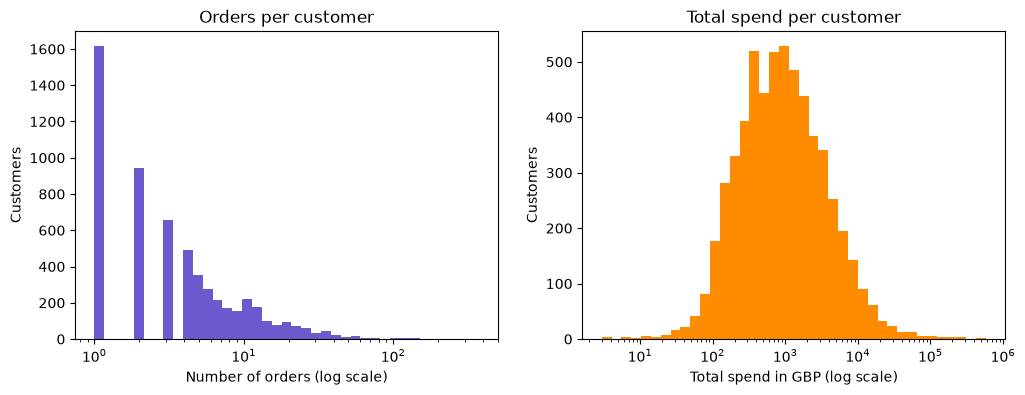

In [10]:
eda.plot_customer_distributions(customers);
print(f"Customers with only one order: {(customers['orders'] == 1).mean():.1%}")

**What it shows:** Most customers place few orders (median 3, and about 28% ordered only once) while a small group orders dozens or hundreds of times. Spend per customer is very spread out (median about 856 GBP, maximum about 581k GBP), so it only looks reasonable on a log scale.

## 6. Outliers in customer spend

IQR outliers (above Q3 + 1.5*IQR): 619
Skewness raw: 25.33   after log1p: 0.27
Share of revenue from top 10% customers: 63.9%


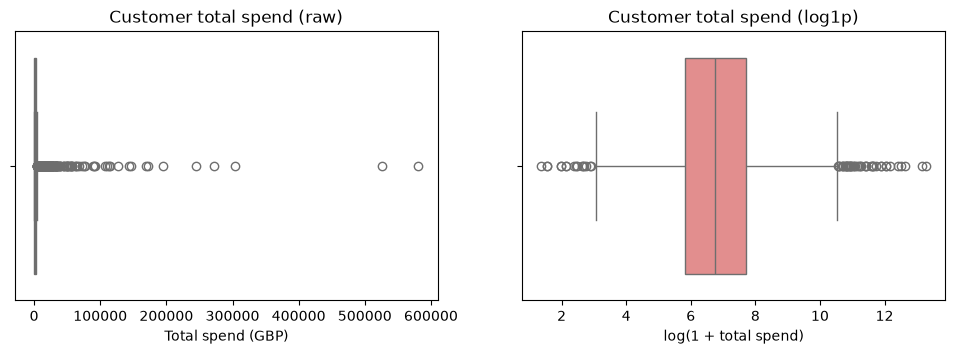

In [11]:
import numpy as np
spend = customers['total_spend']
q1, q3 = spend.quantile([0.25, 0.75])
print(f'IQR outliers (above Q3 + 1.5*IQR): {(spend > q3 + 1.5 * (q3 - q1)).sum():,}')
print(f'Skewness raw: {spend.skew():.2f}   after log1p: {np.log1p(spend).skew():.2f}')
print(f'Share of revenue from top 10% customers: {spend.nlargest(len(spend) // 10).sum() / spend.sum():.1%}')
eda.plot_spend_boxplot(customers);

**What it shows:** On the raw scale the box is squashed near zero and 619 customers are flagged as outliers; the top 10% of customers bring about 64% of revenue. These are real big (wholesale) buyers, not errors, so we keep them. After `log1p` the skewness drops from 25.3 to 0.27, which is why monetary features and the spend target will be log-transformed.